In [1]:
import pandas as pd
import numpy as np

import seaborn as sn
from matplotlib import pyplot as plt

# Figure 1: Combinatorial peptide pooling design.

## C
 The number of possible candidates depends on the
number of tested peptides and the number of erroneous non-activated pools. Results are shown for a pooling
scheme with 18 pools and 6 pools per peptide, and an epitope present in two consecutive peptides. For every
combination of 0–3 pools, we simulated erroneous non-activation and then, for each peptide, measured how
many other peptides had the same resulting activation pattern. For zero erroneously non-activated pools, two
peptides whose shared sequence contains the cognate epitope are retrieved.

In [2]:
simulation_results_fixN18_fixI6 = pd.read_csv('./data/errors_fixN18_fixI6.tsv', sep = "\t")

for i in [100, 200, 300]:
    for j in [0, 1, 2, 3]:
        subset = simulation_results_fixN18_fixI6[(simulation_results_fixN18_fixI6['# of lost'] < 4) & (simulation_results_fixN18_fixI6['Len'] == i) & (simulation_results_fixN18_fixI6['# of lost'] == j)]
        print(i,j, np.median(subset['# of peptides']))

100 0 2.0
100 1 2.0
100 2 3.0
100 3 4.0
200 0 2.0
200 1 2.0
200 2 3.0
200 3 7.0
300 0 2.0
300 1 2.0
300 2 4.0
300 3 9.0


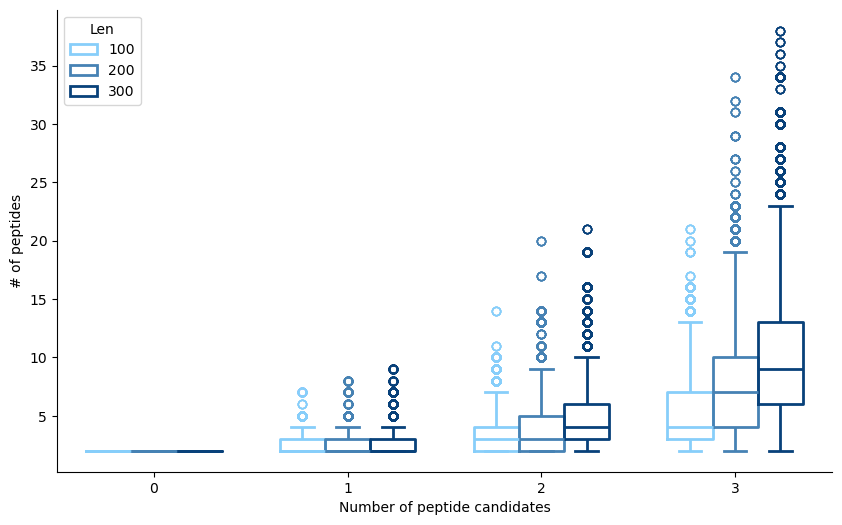

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))
ax = sn.boxplot(data = simulation_results_fixN18_fixI6[simulation_results_fixN18_fixI6['# of lost'] < 4],
                x = '# of lost', y = '# of peptides', hue = 'Len',
                palette = ['#87CEFA', '#4682B4', '#08417A'], fill = False, linewidth = 2, width = 0.7)
ax.set_xlabel('Number of erroneous non-activated pools')
ax.set_xlabel('Number of peptide candidates')
sn.despine()